# Around the Globe Quiz — Project Presentation


This notebook presents the data exploration, statistical analysis, and visualizations for the **Around the Globe Quiz** project.

## 1. Importing Libraries
We import the libraries used across the project:
- `json` to load the geography dataset.
- `pandas` for tabular data structures and data analysis.
- `numpy` for scientific and mathematical calculations.
- `matplotlib.pyplot` for creating charts.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Display charts inline within the notebook
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## 2. Loading the Geography Dataset
The quiz generates questions dynamically using country data stored in `geography_data.json`. We load this file using Python's built-in `json` module.

In [2]:
with open("geography_data.json", "r", encoding="utf-8") as file:
    geography_data = json.load(file)

print(f"Total countries loaded: {len(geography_data)}")
print("Sample country entry:")
print(geography_data[0])

Total countries loaded: 25
Sample country entry:
{'country': 'France', 'capital': 'Paris', 'continent': 'Europe', 'region': 'Western Europe'}


## 3. Dataset Inspection with Pandas
To easily inspect, filter, and summarize the geography dataset, we convert the list of country dictionaries into a Pandas DataFrame.

In [3]:
# Convert to a DataFrame
geo_df = pd.DataFrame(geography_data)

# Display the first 5 countries
geo_df.head()

,country,capital,continent,region
0,France,Paris,Europe,Western Europe
1,Japan,Tokyo,Asia,Eastern Asia
2,Canada,Ottawa,Americas,North America
3,Australia,Canberra,Oceania,Oceania
4,Brazil,Brasilia,Americas,South America


We can inspect the distribution of countries across continents and regions using Pandas `.value_counts()`.

In [4]:
# Number of countries per continent
print("Countries per continent:")
print(geo_df["continent"].value_counts())
print("\nNumber of unique regions represented:", geo_df["region"].nunique())

Countries per continent:
continent
Europe      10
Asia         6
Americas     4
Africa       4
Oceania      1
Name: count, dtype: int64

Number of unique regions represented: 14


## 4. Loading Quiz History with Pandas
Every finished quiz automatically saves the date, difficulty, score, max score, and accuracy to `quiz_history.csv`. We load this history into a DataFrame.

In [5]:
history_df = pd.read_csv("quiz_history.csv")

# Display the full history table
history_df

,date_time,difficulty,score,max_score,accuracy_pct
0,2026-11-06 23:07:28,Easy,0,5,0.0
1,2026-11-06 23:07:36,Medium,2,10,20.0
2,2026-11-06 23:07:44,Hard,0,15,0.0
3,2026-11-06 23:07:57,Easy,2,5,40.0
4,2026-11-06 23:15:15,Medium,10,10,100.0
5,2026-11-08 20:09:38,Hard,15,15,100.0
6,2026-11-12 17:01:27,Easy,1,5,20.0
7,2026-11-12 17:01:38,Medium,0,10,0.0
8,2026-11-12 17:01:49,Hard,3,15,20.0
9,2026-11-12 17:38:53,Easy,0,5,0.0


## 5. Statistical Analysis with NumPy and Pandas
We compute the main performance statistics:
- **Total games played:** computed using `len()`.
- **Overall average accuracy:** computed using NumPy's `np.mean()`.
- **Highest accuracy:** computed using Pandas `.max()`.
- **Performance by difficulty:** grouped and summarized using Pandas `.groupby()`, `.count()`, and `.mean()`.

In [6]:
# Overall calculations
total_games = len(history_df)
average_accuracy = np.mean(history_df["accuracy_pct"])
highest_accuracy = history_df["accuracy_pct"].max()

print("=" * 40)
print(f"Total games played: {total_games}")
print(f"Overall average accuracy (NumPy): {average_accuracy:.2f}%")
print(f"Highest accuracy (Pandas):        {highest_accuracy:.2f}%")
print("=" * 40)

# Performance by difficulty using Pandas groupby
diff_counts = history_df.groupby("difficulty")["accuracy_pct"].count()
diff_averages = history_df.groupby("difficulty")["accuracy_pct"].mean()

print("\nPerformance by Difficulty (Pandas):")
for diff in ["Easy", "Medium", "Hard"]:
    if diff in diff_counts:
        print(f"  {diff:<6} -> Games: {diff_counts[diff]} | Average Accuracy: {diff_averages[diff]:.2f}%")

Total games played: 17
Overall average accuracy (NumPy): 37.65%
Highest accuracy (Pandas):        100.00%

Performance by Difficulty (Pandas):
  Easy   -> Games: 8 | Average Accuracy: 25.00%
  Medium -> Games: 5 | Average Accuracy: 48.00%
  Hard   -> Games: 4 | Average Accuracy: 50.00%


## 6. Visualizations with Matplotlib
We visualize the quiz performance using three separate charts:
1. **Bar Chart:** Average accuracy for each difficulty level (Easy, Medium, Hard).
2. **Line Chart:** Accuracy over time across all games played.
3. **Pie Chart:** Proportion of games played at each difficulty level.

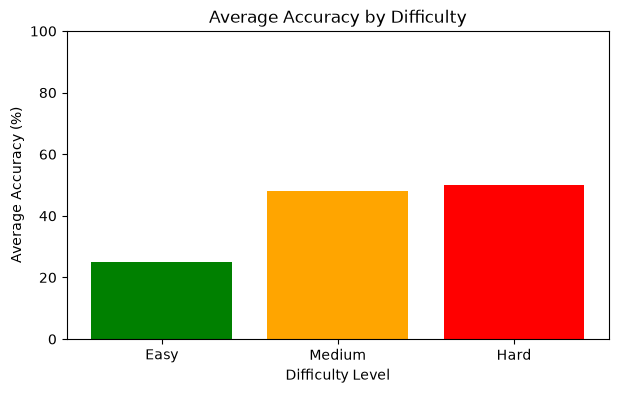

In [7]:
# 1. Bar Chart: Average Accuracy by Difficulty
difficulties = ["Easy", "Medium", "Hard"]
avg_accuracies = []
for d in difficulties:
    if d in diff_averages:
        avg_accuracies.append(diff_averages[d])
    else:
        avg_accuracies.append(0.0)

plt.figure(figsize=(7, 4))
plt.bar(difficulties, avg_accuracies, color=["green", "orange", "red"])
plt.title("Average Accuracy by Difficulty")
plt.xlabel("Difficulty Level")
plt.ylabel("Average Accuracy (%)")
plt.ylim(0, 100)
plt.show()

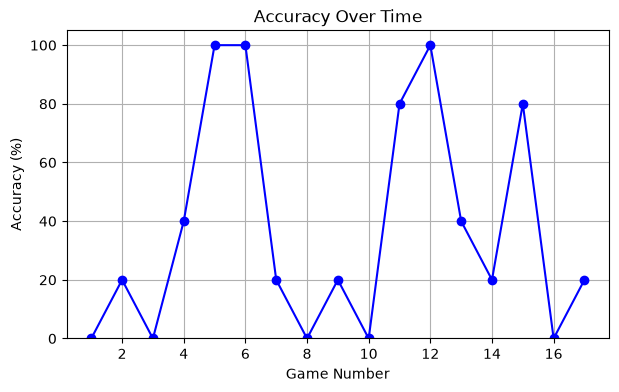

In [8]:
# 2. Line Chart: Accuracy Over Time
game_numbers = list(range(1, len(history_df) + 1))

plt.figure(figsize=(7, 4))
plt.plot(game_numbers, history_df["accuracy_pct"], marker="o", color="blue")
plt.title("Accuracy Over Time")
plt.xlabel("Game Number")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.show()

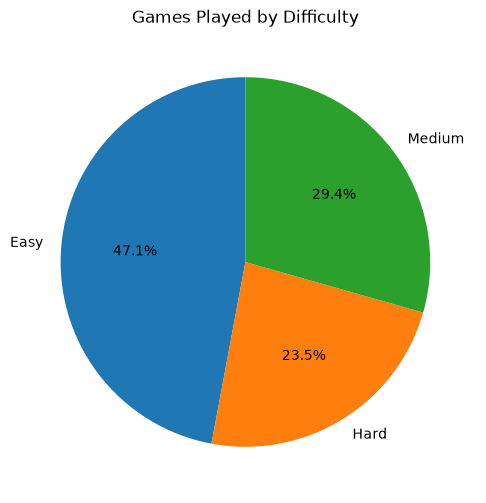

In [9]:
# 3. Pie Chart: Games Played by Difficulty
played_labels = list(diff_counts.index)
played_counts = list(diff_counts.values)

plt.figure(figsize=(6, 6))
plt.pie(played_counts, labels=played_labels, autopct="%1.1f%%", startangle=90)
plt.title("Games Played by Difficulty")
plt.show()

## 7. Running the Quiz
You can run the full interactive quiz directly inside Jupyter Notebook using the `%run` command below.

When prompted, enter your difficulty choice (`1`, `2`, or `3`) and answer each question with `A`, `B`, `C`, or `D`.

Alternatively, you can run the quiz anytime from your terminal:
```bash
python quiz.py
```

   Welcome to Around the Globe Quiz!

Select your difficulty level:
  1 - Easy
  2 - Medium
  3 - Hard

You selected: Hard (3 point(s) per correct answer)
Let's begin!

Question 1 of 5
What is the capital of Morocco?
  A) Pretoria
  B) Rabat
  C) Cairo
  D) Nairobi
Invalid input. Please enter A, B, C or D.
Wrong! The correct answer was B (Rabat).

Question 2 of 5
What is the capital of South Korea?
  A) Tokyo
  B) New Delhi
  C) Seoul
  D) Hanoi
Correct! +3 point(s)

Question 3 of 5
What is the capital of Germany?
  A) Berlin
  B) Athens
  C) Paris
  D) London
Wrong! The correct answer was A (Berlin).

Question 4 of 5
What is the capital of South Africa?
  A) Rabat
  B) Cairo
  C) Pretoria
  D) Nairobi
Correct! +3 point(s)

Question 5 of 5
What is the capital of Thailand?
  A) Bangkok
  B) Hanoi
  C) Ankara
  D) Seoul
Wrong! The correct answer was A (Bangkok).

Quiz complete! Your score: 6 out of 15 points
Accuracy: 40.00%
Not bad! Keep practising.

Review Your Mistakes:
--------------

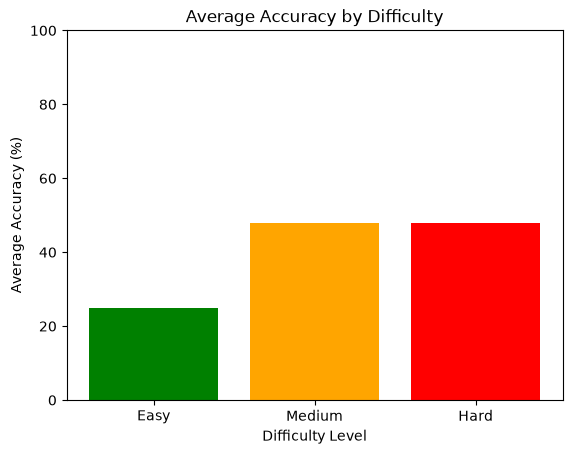

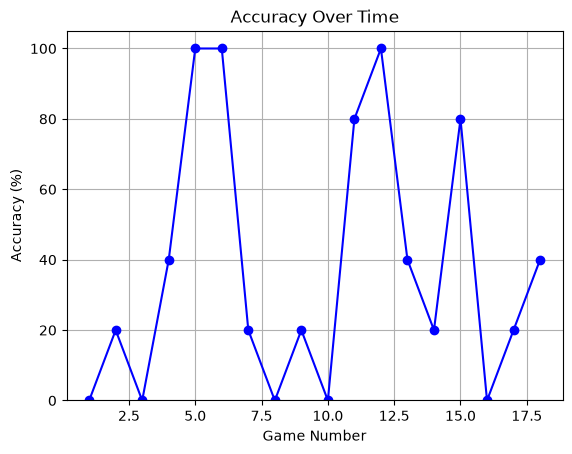

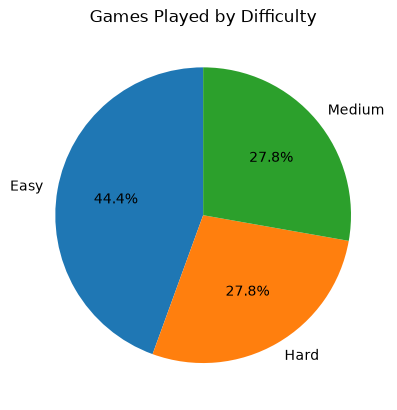

<Figure size 640x480 with 0 Axes>

In [10]:
# Run the interactive quiz from quiz.py
%run quiz.py